Ejercicio 2.1.- Análisis Exploratorio con Pandas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# URL del dataset de pingüinos de Palmer
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df = pd.read_csv(url)
print(df.head())

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
3          NaN     NaN  
4       3450.0  FEMALE  


In [3]:
# Identificar si existen valores nulos y eliminarlos.
print(df.isnull().sum())
critical_data = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
df_clean = df.dropna(subset=critical_data)

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [4]:
print(df_clean.head())
print(df_clean.isnull().sum())

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
4       3450.0  FEMALE  
5       3650.0    MALE  
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64


In [5]:
# Calcular la masa corporal promedio por cada especie y por isla.
average_mass = df.groupby(['species', 'island'])['body_mass_g'].mean().reset_index()
print('Masa corporal promedio por especie e isla:')
display(average_mass)

Masa corporal promedio por especie e isla:


,species,island,body_mass_g
0,Adelie,Biscoe,3709.659091
1,Adelie,Dream,3688.392857
2,Adelie,Torgersen,3706.372549
3,Chinstrap,Dream,3733.088235
4,Gentoo,Biscoe,5076.016260


In [6]:
gentoo_heavy = df_clean[(df_clean['species'] == 'Gentoo') & (df_clean['body_mass_g'] > 5000)]
print(gentoo_heavy.head())

    species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
221  Gentoo  Biscoe            50.0           16.3              230.0   
223  Gentoo  Biscoe            50.0           15.2              218.0   
224  Gentoo  Biscoe            47.6           14.5              215.0   
227  Gentoo  Biscoe            46.7           15.3              219.0   
229  Gentoo  Biscoe            46.8           15.4              215.0   

     body_mass_g   sex  
221       5700.0  MALE  
223       5700.0  MALE  
224       5400.0  MALE  
227       5200.0  MALE  
229       5150.0  MALE  


Ejercicio 2.2.- Procesamiento de Señales con NumPy

In [7]:
# Extraer las columnas bill_length_mm y bill_depth_mm
# y convertirlas en una matriz de NumPy de N/2
bill_size = df_clean[['bill_length_mm', 'bill_depth_mm']].values
print(bill_size[:5])

[[39.1 18.7]
 [39.5 17.4]
 [40.3 18. ]
 [36.7 19.3]
 [39.3 20.6]]


In [8]:
# Crear un nuevo array que sea el resultado de
# dividir el largo entre el alto para cada pingüino.
bill_proportion = bill_size[:, 0] / bill_size[:, 1]
print(bill_proportion[:5])

[2.09090909 2.27011494 2.23888889 1.9015544  1.90776699]


In [9]:
# Utiliza una función de NumPy para encontrar qué pingüinos
# tienen un largo de pico que esté a más de 2 desviaciones
# estándar de la media del grupo.
df_bill_lenght = df_clean
desv = df_bill_lenght['bill_length_mm'].std()
average = df_bill_lenght['bill_length_mm'].mean()
print(len(df_bill_lenght))
outliers = df_bill_lenght[(np.abs(df_bill_lenght['bill_length_mm'] - average) / desv) > 2]
print(outliers)

342
       species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
142     Adelie   Dream            32.1           15.5              188.0   
169  Chinstrap   Dream            58.0           17.8              181.0   
215  Chinstrap   Dream            55.8           19.8              207.0   
253     Gentoo  Biscoe            59.6           17.0              230.0   
321     Gentoo  Biscoe            55.9           17.0              228.0   
335     Gentoo  Biscoe            55.1           16.0              230.0   

     body_mass_g     sex  
142       3050.0  FEMALE  
169       3700.0  FEMALE  
215       4000.0    MALE  
253       6050.0    MALE  
321       5600.0    MALE  
335       5850.0    MALE  


In [10]:
# Extrae solo los datos de los pingüinos que están en las
# posiciones pares del array original.
df_sp = df[df.index % 2 == 0]
print(df_sp)

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0    Adelie  Torgersen            39.1           18.7              181.0   
2    Adelie  Torgersen            40.3           18.0              195.0   
4    Adelie  Torgersen            36.7           19.3              193.0   
6    Adelie  Torgersen            38.9           17.8              181.0   
8    Adelie  Torgersen            34.1           18.1              193.0   
..      ...        ...             ...            ...                ...   
334  Gentoo     Biscoe            46.2           14.1              217.0   
336  Gentoo     Biscoe            44.5           15.7              217.0   
338  Gentoo     Biscoe            47.2           13.7              214.0   
340  Gentoo     Biscoe            46.8           14.3              215.0   
342  Gentoo     Biscoe            45.2           14.8              212.0   

     body_mass_g     sex  
0         3750.0    MALE  
2         3250.0  FEMALE  
4     

Ejercicio 2.3.- Visualización Científica con Matplotlib

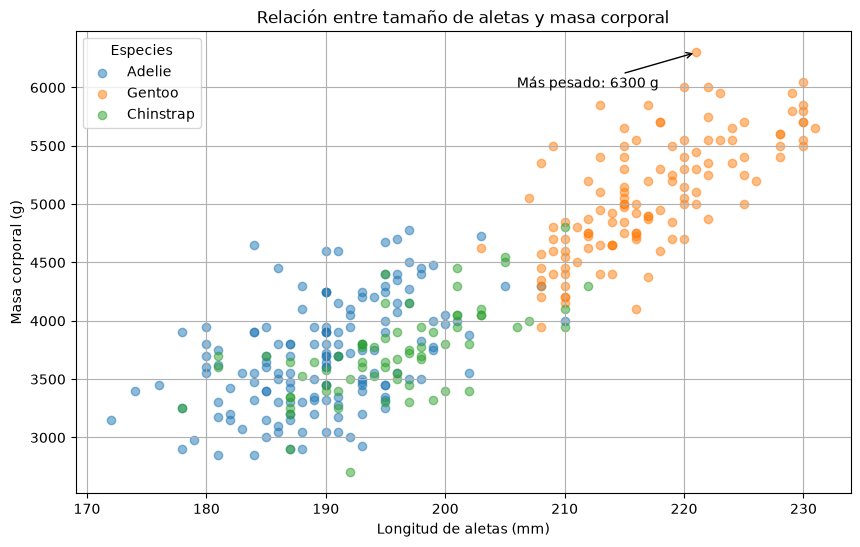

In [11]:
# Graficar flipper_length_mm (aletas) en el eje X y body_mass_g en el eje Y.

df_adelie = df_clean[df_clean['species'] == 'Adelie']
df_gentoo = df_clean[df_clean['species'] == 'Gentoo']
df_chinstrap = df_clean[df_clean['species'] == 'Chinstrap']

plt.figure(figsize=(10, 6))
plt.scatter(df_adelie['flipper_length_mm'], df_adelie['body_mass_g'], label='Adelie', alpha=0.5)
plt.scatter(df_gentoo['flipper_length_mm'], df_gentoo['body_mass_g'], label='Gentoo', alpha=0.5)
plt.scatter(df_chinstrap['flipper_length_mm'], df_chinstrap['body_mass_g'], label='Chinstrap', alpha=0.5)


heaviest = df_clean.loc[df_clean['body_mass_g'].idxmax()]
plt.annotate('Más pesado: %d g' % heaviest['body_mass_g'],
             xy=(heaviest['flipper_length_mm'], heaviest['body_mass_g']),
             xytext=(heaviest['flipper_length_mm'] - 15, heaviest['body_mass_g'] - 300),
             arrowprops=dict(arrowstyle='->', lw=1))

plt.title('Relación entre tamaño de aletas y masa corporal')
plt.xlabel('Longitud de aletas (mm)')
plt.ylabel('Masa corporal (g)')
plt.grid(True)
plt.legend(title='Especies')
plt.show()

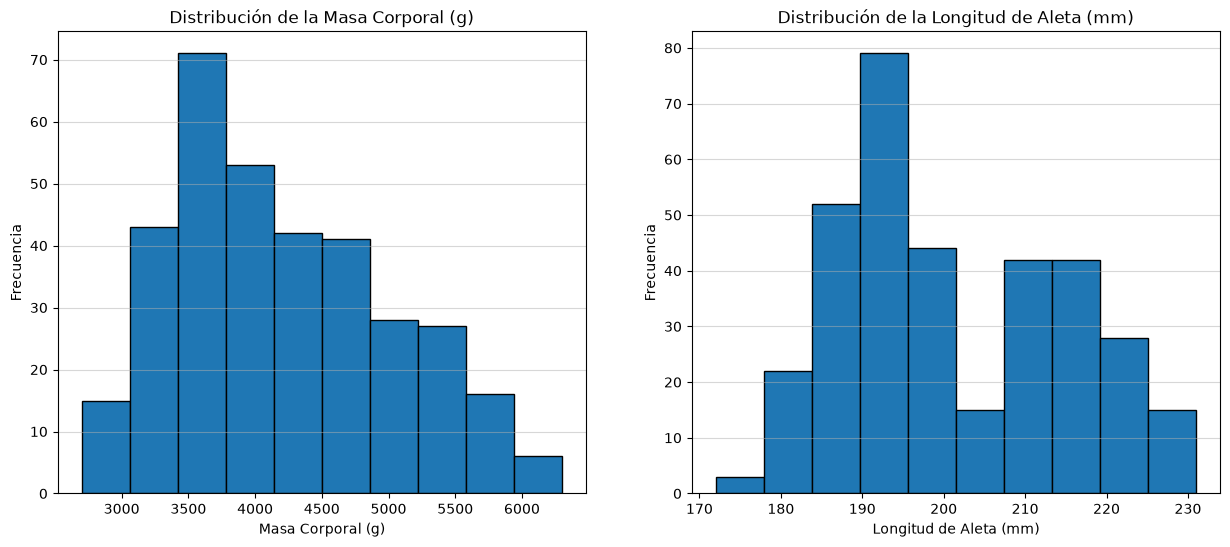

In [12]:
# Crea una figura con dos "subplots", uno con la masa corporal
# y otro con el tamaño de las aletas.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].hist(df_clean['body_mass_g'], edgecolor='black')
axes[0].set_title('Distribución de la Masa Corporal (g)')
axes[0].set_xlabel('Masa Corporal (g)')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(axis='y', alpha=0.5)

axes[1].hist(df_clean['flipper_length_mm'], edgecolor='black')
axes[1].set_title('Distribución de la Longitud de Aleta (mm)')
axes[1].set_xlabel('Longitud de Aleta (mm)')
axes[1].set_ylabel('Frecuencia')
axes[1].grid(axis='y', alpha=0.5)

plt.show()